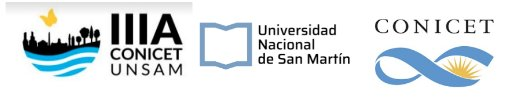  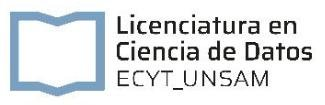

---

# NB11 — Detección de cambios: lo que cambió en una década

Lo que veremos en esta notebook:

- [x] El problema de detectar cambios entre dos imágenes de distinta fecha
- [x] Análisis basado en índices: diferencia de NDVI, umbrales y significancia
- [x] Análisis post-clasificación: matriz de transición entre clases
- [x] El trade-off entre detección píxel a píxel y detección por unidad areal
- [x] Asignación de causas: la intersección con el territorio social
---

### Objetivos de la notebook

Al terminar esta clase esperamos que puedas:

- Distinguir los dos enfoques principales de detección de cambios: basado en índices y post-clasificación.
- Elegir un umbral de cambio significativo basado en variabilidad natural del índice.
- Construir e interpretar una matriz de transición de clases entre dos épocas.
- Identificar las trayectorias de cambio territorialmente más relevantes (urbanización, pérdida vegetal).
- Agregar las estadísticas de cambio a unidades areales (radios) para conectar con análisis socioeconómicos.

### Datos con los que trabajaremos

Productos de notebooks anteriores:

- `../data/proc/ndvi_completo_2015ago.tif` y `../data/proc/ndvi_completo_2025ago.tif` — NDVI de agosto 2015 y agosto 2025 (construidos en el curso).
- `../data/proc/dataset_etiquetado_corregido.npz` — sólo para recuperar el orden canónico de clases del raster del mapa.
- `../data/proc/mapa_cobertura_dique_2026feb.tif` — mapa de cobertura actual.
- `../data/proc/mapa_cobertura_dique_2015ago.tif` — mapa de cobertura histórico (construido en el **Ejercicio 3 de NB08**).
- `../data/proc/radios_con_lisa_gi.gpkg` — radios con variables socioeconómicas y hotspots LISA / Gi*.

### Conexión con el arco del curso

El curso eligió tres imágenes con una lógica temporal explícita (2015 ago, 2025 ago, 2026 feb) para poder separar cambio real de variación estacional. Esta notebook materializa ese diseño: usamos el par agosto-agosto para detectar **cambios reales** libres de estacionalidad.

La notebook integra productos de varias clases anteriores: los mapas de cobertura y los radios con análisis LISA. Las estadísticas de cambio por radio son uno de los insumos finales de la regresión espacial integradora: el modelo va a preguntarse si la pérdida de cobertura vegetal se acopla con indicadores de vulnerabilidad social.

> **Nota importante:** esta notebook asume que ejecutaste el **Ejercicio 3 de NB08** en el que entrenaste un Random Forest sobre la imagen de 2015 y generaste `mapa_cobertura_dique_2015ago.tif`. Si no lo hiciste, en la sección 3 explicamos cómo reproducir una versión simplificada.

---
# 0. Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
import geopandas as gpd
from matplotlib.colors import ListedColormap

from ade_tools import guardar_geotiff, estadisticas_zonales

RAW  = '../data/raw_data/'
PROC = '../data/proc/'

FN_NDVI_2015    = PROC + 'ndvi_completo_2015ago.tif'
FN_NDVI_2025    = PROC + 'ndvi_completo_2025ago.tif'
FN_MAPA_2026    = PROC + 'mapa_cobertura_dique_2026feb.tif'
FN_MAPA_2015    = PROC + 'mapa_cobertura_dique_2015ago.tif'
FN_DATASET      = PROC + 'dataset_etiquetado_corregido.npz'
FN_ZONA         = RAW  + 'vectorial/zona_dique.geojson'
FN_RADIOS_LISA  = PROC + 'radios_con_lisa_gi.gpkg'

---
# 1. Dos enfoques para detectar cambios

Los métodos de detección de cambios en teledetección se agrupan en dos familias principales (Singh, 1989; Lu et al. 2004; Tewkesbury et al. 2015):

### 1.1 Basado en índices (algebra de bandas)

Se calcula un índice (NDVI, NDWI, brillo) para cada época y se opera sobre ellos: diferencia, cociente, componente principal de la diferencia, etc. La salida es continua: un valor numérico por píxel que representa la "magnitud del cambio". Simple, rápido, detecta cambios sutiles. Pero no dice **qué tipo** de cambio ocurrió —un píxel que pasa de NDVI 0.7 a 0.4 podría ser urbanización, pérdida forestal, sequía estacional, o error de calibración.

### 1.2 Post-clasificación

Se clasifica cada imagen de forma independiente (NB08) y se cruzan los dos mapas resultantes: para cada píxel se tiene el par (clase$_{t_0}$, clase$_{t_1}$). Responde "qué" cambió (clase A → clase B) pero hereda los errores de ambas clasificaciones — si cada mapa tiene 85% de accuracy, la detección de cambios tiene como mucho $0.85 \times 0.85 \approx 72$% de exactitud sin tipo de error.

Usamos los dos enfoques: complementarios. El basado en índices da una vista continua; el post-clasificación da una tabla de transiciones interpretable.

---
# 2. Análisis basado en ΔNDVI

### 2.0 Confirmación de insumos

Las notebooks anteriores (autocorrelación espacial) generaron ambos NDVIs (ago 2015 y ago 2025) como parte de su análisis. Verificamos que existan; si no, los construimos ahora. Recordá que usamos comparación **ago-ago** precisamente para neutralizar la estacionalidad y atribuir el ΔNDVI a cambio real del territorio.

In [ ]:
import os
from ade_tools import guardar_geotiff

def construir_ndvi_si_no_existe(fn_img_s2, fn_ndvi_out, nombre_banda='NDVI'):
    """Construye NDVI a partir de imagen S2 B02B03B04B08 si el archivo destino no existe."""
    if os.path.exists(fn_ndvi_out):
        print(f'Ya existe: {fn_ndvi_out}')
        return
    with rasterio.open(fn_img_s2) as src:
        im = src.read().astype(float)
        perfil = src.profile.copy()
    ESC = 10_000.0
    OFFSET = -1_000.0                    # BOA_ADD_OFFSET: ambas fechas lo tienen (NB02 §3)
    valido = np.all(im != 0, axis=0)     # sobre el DN crudo, antes del offset
    rojo = (im[2] + OFFSET) / ESC
    nir  = (im[3] + OFFSET) / ESC
    ndvi = np.where(valido & ((nir+rojo) != 0), (nir-rojo)/(nir+rojo), np.nan).astype(np.float32)
    guardar_geotiff(fn_ndvi_out, ndvi, perfil, nodata=np.nan, nombres_bandas=[nombre_banda])

construir_ndvi_si_no_existe(RAW + 'satelital/S2_AMBANO_B02B03B04B08_2015ago.tif',
                             FN_NDVI_2015, 'NDVI_2015ago')
construir_ndvi_si_no_existe(RAW + 'satelital/S2_AMBANO_B02B03B04B08_2025ago.tif',
                             FN_NDVI_2025, 'NDVI_2025ago')

In [ ]:
with rasterio.open(FN_NDVI_2015) as s1, rasterio.open(FN_NDVI_2025) as s2:
    ndvi_2015 = s1.read(1).astype(float)
    ndvi_2025 = s2.read(1).astype(float)
    perfil = s1.profile.copy()

# Aseguramos misma forma (deberían coincidir ya desde NB02)
assert ndvi_2015.shape == ndvi_2025.shape, f'{ndvi_2015.shape} vs {ndvi_2025.shape}'

# Diferencia
delta = ndvi_2025 - ndvi_2015

# Estadísticas básicas
valido = ~np.isnan(delta)
print(f'Píxeles válidos en ambas épocas: {valido.sum():,}')
print(f'ΔNDVI: media {np.nanmean(delta):+.3f}, mediana {np.nanmedian(delta):+.3f}, std {np.nanstd(delta):.3f}')
print(f'      percentiles 1-99: [{np.nanpercentile(delta, 1):+.2f}, {np.nanpercentile(delta, 99):+.2f}]')

## 2.1 Elección de umbral de cambio

No todo ΔNDVI distinto de cero es un "cambio real": hay ruido instrumental, correcciones atmosféricas imperfectas, cambio estacional residual (aun agosto-agosto puede variar), y variabilidad interanual natural. Un enfoque clásico para elegir un umbral (Singh, 1989):

1. Calcular la distribución de ΔNDVI sobre una región "estable" (zonas donde sabemos que no hubo cambio — por ejemplo, el centro del espejo de agua del dique).
2. Tomar como umbral $\pm 2\sigma$ o percentiles 2.5-97.5 de esa distribución estable.
3. Los píxeles fuera del umbral son "cambios significativos".

Implementación práctica: usamos la masa de datos global (centrada en ~0) y asumimos que el grueso es no-cambio. El umbral en $\pm 2 \sigma$ es una heurística razonable si la distribución no está muy sesgada.

> **Alternativa robusta.** La desviación estándar $\sigma$ es sensible a outliers — exactamente los píxeles que queremos identificar como cambio inflan nuestro umbral. Un estimador **robusto** habitual es $\sigma \approx 1.4826 \cdot \text{MAD}$, donde MAD (*Median Absolute Deviation*) es la mediana de $|\Delta\text{NDVI} - \text{mediana}|$. Para una distribución gaussiana las dos dan lo mismo; para distribuciones contaminadas con outliers, la MAD no se infla. Lo pedimos en el Ejercicio 1.

In [ ]:
# Umbral ±2σ del grueso de la distribución (excluyendo colas extremas)
sigma = np.nanstd(delta[(delta > np.nanpercentile(delta, 5)) &
                          (delta < np.nanpercentile(delta, 95))])
umbral = 2 * sigma
print(f'σ robusta (central 90%): {sigma:.3f}')
print(f'Umbral ±2σ              : ±{umbral:.3f}')

# Clasificación ternaria
clase_cambio = np.full(delta.shape, 0, dtype=int)  # 0 = sin cambio
clase_cambio[delta > umbral]  = 1  # ganancia de vegetación
clase_cambio[delta < -umbral] = 2  # pérdida de vegetación
clase_cambio[~valido] = -1

n_ganancia = (clase_cambio == 1).sum()
n_perdida  = (clase_cambio == 2).sum()
n_estable  = (clase_cambio == 0).sum()
n_total    = valido.sum()

print(f'\nGanancia   : {n_ganancia:8,} píxeles ({n_ganancia/n_total*100:.1f}%)')
print(f'Sin cambio : {n_estable:8,} píxeles ({n_estable/n_total*100:.1f}%)')
print(f'Pérdida    : {n_perdida:8,} píxeles ({n_perdida/n_total*100:.1f}%)')

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.set_facecolor('white')

# Histograma de ΔNDVI
axes[0].hist(delta[valido], bins=100, color='gray', edgecolor='white')
axes[0].axvline(umbral,  color='green', ls='--', label=f'+{umbral:.2f}')
axes[0].axvline(-umbral, color='red',   ls='--', label=f'-{umbral:.2f}')
axes[0].axvline(0, color='black', linewidth=0.5)
axes[0].set_xlabel('ΔNDVI'); axes[0].set_ylabel('Cantidad de píxeles')
axes[0].set_title('Distribución de ΔNDVI 2015 → 2025')
axes[0].legend()

# ΔNDVI continuo
im = axes[1].imshow(delta, cmap='RdYlGn', vmin=-0.4, vmax=0.4)
axes[1].set_title('ΔNDVI (verde = ganancia, rojo = pérdida)')
axes[1].axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.03)

# Clases de cambio
cmap_cambio = ListedColormap(['#d62728','lightgray','#2ca02c'])
im2 = axes[2].imshow(np.where(clase_cambio == -1, np.nan, clase_cambio),
                       cmap=cmap_cambio, vmin=0, vmax=2)
axes[2].set_title('Clases de cambio (±2σ)')
axes[2].axis('off')
# Leyenda
from matplotlib.patches import Patch
leg = [Patch(color='#2ca02c', label='Ganancia'),
       Patch(color='lightgray', label='Sin cambio'),
       Patch(color='#d62728', label='Pérdida')]
axes[2].legend(handles=leg, loc='lower left', fontsize=9)

plt.tight_layout()
plt.show()

---
# 3. Análisis post-clasificación: matriz de transición

Con los dos mapas de cobertura (2015 y 2026) hacemos una tabla cruzada: para cada par de clases (desde, hacia), cuántos píxeles hicieron esa transición.

Es una matriz no simétrica: la fila $i$ es la clase en 2015, la columna $j$ es la clase en 2026 y $m_{ij}$ es el número de píxeles. La diagonal es estabilidad (misma clase en ambas épocas); fuera de la diagonal, el cambio.

In [ ]:
# Si no ejecutaste el Ejercicio 3 de NB08, este bloque va a fallar.
# Alternativa rápida: construir un proxy del mapa 2015 entrenando un RF sobre
# los clusters GMM aplicados a la imagen de 2015. No es ideal —los clusters no
# están etiquetados con las 6 clases del curso— pero permite hacer el análisis
# posterior. Idealmente: correr el Ejercicio 3 de la NB de clasificación supervisada.

import os
if not os.path.exists(FN_MAPA_2015):
    raise FileNotFoundError(
        f'No existe {FN_MAPA_2015}. Este archivo se genera en el Ejercicio 3 '
        'de la NB de clasificación supervisada. Si lo saltaste, re-hacelo antes '
        'de continuar. Sin ese mapa, la sección post-clasificación no se puede correr.'
    )

with rasterio.open(FN_MAPA_2015) as src: mapa_2015 = src.read(1)
with rasterio.open(FN_MAPA_2026) as src: mapa_2026 = src.read(1)

# Alineamos: ambos deben tener misma forma
if mapa_2015.shape != mapa_2026.shape:
    raise ValueError(f'Shapes distintos: {mapa_2015.shape} vs {mapa_2026.shape}')

# Orden canónico de clases: lo derivamos del MISMO dataset corregido que usó la
# notebook de clasificación supervisada al guardar el raster del mapa. Es CRÍTICO
# que coincida con la codificación 1..K del raster.
data_etiq = np.load(FN_DATASET, allow_pickle=True)
CLASES_ORD = tuple(sorted(np.unique(data_etiq['y'])))
clases = list(CLASES_ORD)
clase_to_int = {c: i+1 for i, c in enumerate(clases)}
int_to_clase = {v: k for k, v in clase_to_int.items()}
print(f'Orden canónico ({len(clases)} clases): {clases}')

# Matriz de transición: considerando solo píxeles válidos en ambos
mask = (mapa_2015 > 0) & (mapa_2026 > 0)
M = pd.crosstab(
    pd.Series(mapa_2015[mask]).map(int_to_clase),
    pd.Series(mapa_2026[mask]).map(int_to_clase)
).reindex(index=clases, columns=clases, fill_value=0)

# Hectáreas (asumiendo 10m de resolución)
AREA_PX_HA = 100 / 10000
M_ha = M * AREA_PX_HA
print('\nMatriz de transición (hectáreas):')
print(M_ha.round(0).astype(int))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
fig.set_facecolor('white')

# Heatmap crudo
sns.heatmap(M_ha, annot=True, fmt='.0f', cmap='Oranges', ax=axes[0],
            cbar_kws={'label':'ha'})
axes[0].set_xlabel('Clase 2026'); axes[0].set_ylabel('Clase 2015')
axes[0].set_title('Matriz de transición (ha)')

# Normalizada por fila: % de cada clase 2015 que fue a cada clase 2026
M_norm = M_ha.div(M_ha.sum(axis=1), axis=0) * 100
sns.heatmap(M_norm, annot=True, fmt='.1f', cmap='Blues', ax=axes[1],
            cbar_kws={'label':'%'})
axes[1].set_xlabel('Clase 2026'); axes[1].set_ylabel('Clase 2015')
axes[1].set_title('Transiciones como % de la clase origen')

plt.suptitle('De dónde viene y a dónde va cada clase (2015 → 2026)', fontsize=13)
plt.tight_layout()
plt.show()

Lecturas típicas de la matriz:

- **Diagonal alta** = clase estable en el territorio. Agua suele ser la más estable.
- **Transición `bosque → urbano` alta** = señal clara de **urbanización expansiva**: pérdida de vegetación convertida en tejido urbano.
- **Transición de las subclases rurales hacia `urbano`** alta = consolidación urbana de tierras antes ocupadas por pastizal o suelo desnudo.
- **Transición `urbano → bosque` alta** = sospechosa: el tejido urbano no suele revertir. Puede indicar error de clasificación en alguno de los dos mapas o, en casos puntuales, parques recién construidos.

---
# 4. Transiciones clave y su localización

In [ ]:
# Identificamos las 3 transiciones más grandes fuera de la diagonal
M_off = M_ha.copy()
np.fill_diagonal(M_off.values, 0)

# Top transiciones ordenadas
transiciones = []
for i, c_from in enumerate(clases):
    for j, c_to in enumerate(clases):
        if i != j:
            transiciones.append((c_from, c_to, M_off.loc[c_from, c_to]))

transiciones.sort(key=lambda x: x[2], reverse=True)
print('Top 10 transiciones por hectáreas (2015 → 2026):')
for c_from, c_to, ha in transiciones[:10]:
    print(f'  {c_from:15s} → {c_to:15s}: {ha:8.0f} ha')

In [ ]:
# Mapa de las transiciones más relevantes: destacamos bosque→urbano
# y el inverso urbano→bosque por si el mapa tiene errores sistemáticos.
# Usamos los nombres canónicos fijos del esquema; las dos subclases rurales
# tienen nombres definidos por cada estudiante y no se referencian acá.
c1, c2 = clase_to_int['bosque'], clase_to_int['urbano']

urbanizacion = (mapa_2015 == c1) & (mapa_2026 == c2)
reverso      = (mapa_2015 == c2) & (mapa_2026 == c1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.set_facecolor('white')

axes[0].imshow(np.where(mapa_2015 > 0, mapa_2015, np.nan),
                cmap='tab10', vmin=1, vmax=len(clases))
axes[0].set_title('Cobertura 2015'); axes[0].axis('off')

axes[1].imshow(np.where(mapa_2026 > 0, mapa_2026, np.nan),
                cmap='tab10', vmin=1, vmax=len(clases))
axes[1].set_title('Cobertura 2026'); axes[1].axis('off')

# Base de referencia + máscara de urbanización
base = np.where(mapa_2026 > 0, 0.5, np.nan)
cambio_mask = np.full_like(base, np.nan, dtype=float)
cambio_mask[urbanizacion] = 1
cambio_mask[reverso]       = 2

axes[2].imshow(base, cmap='gray', alpha=0.3)
axes[2].imshow(cambio_mask, cmap=ListedColormap(['red','purple']), vmin=1, vmax=2)
axes[2].set_title('Rojo: bosque → urbano\nPúrpura: urbano → bosque (sospechoso)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

---
# 5. Productos guardados

In [ ]:
# ΔNDVI continuo
guardar_geotiff(PROC + 'delta_ndvi_15_25.tif',
                delta.astype(np.float32), perfil,
                nodata=np.nan, nombres_bandas=['delta_ndvi'])

# Mapa ternario
guardar_geotiff(PROC + 'cambio_ndvi_15_25.tif',
                clase_cambio.astype(np.int8), perfil,
                nodata=-1, nombres_bandas=['clase_cambio'])

# Mapa de transiciones (clase 2015 * 10 + clase 2026)
# Ejemplo: clase_2015 × 10 + clase_2026, donde los enteros 1..K siguen
# el orden alfabético del dataset corregido (ver sección 3).
transicion = mapa_2015.astype(int) * 10 + mapa_2026.astype(int)
transicion[(mapa_2015 == 0) | (mapa_2026 == 0)] = 0

guardar_geotiff(PROC + 'mapa_transiciones_15_26.tif',
                transicion.astype(np.int16), perfil,
                nodata=0, nombres_bandas=['transicion'])

# CSV con todas las transiciones como tabla
M_ha.to_csv(PROC + 'transiciones_15_26.csv', index_label='desde_2015')

print('Guardados:')
print(f'  {PROC}delta_ndvi_15_25.tif')
print(f'  {PROC}cambio_ndvi_15_25.tif')
print(f'  {PROC}mapa_transiciones_15_26.tif')
print(f'  {PROC}transiciones_15_26.csv')

---
# 6. Agregación del cambio a radios censales

Para conectar la detección de cambios con el análisis socioeconómico tenemos que agregar las estadísticas de cambio por radio. Dos variables clave:

- **ΔNDVI mediano por radio**: la caída/ganancia de cobertura vegetal típica.
- **% del radio urbanizado** entre 2015 y 2026: proporción de píxeles que hicieron la transición `bosque → urbano`.

Estas dos variables son insumos directos para el modelo de regresión espacial integradora del final del curso.

In [ ]:
# ΔNDVI por radio
gdf = gpd.read_file(FN_RADIOS_LISA)
with rasterio.open(PROC + 'delta_ndvi_15_25.tif') as src:
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

stats_d = estadisticas_zonales(PROC + 'delta_ndvi_15_25.tif', gdf,
                                stats=('median','mean','std'), banda=1)
stats_d.columns = ['delta_ndvi_mediana','delta_ndvi_media','delta_ndvi_std']
gdf = gdf.join(stats_d)

# % urbanizado por radio: contamos píxeles con transición `bosque → urbano`.
# Reescribimos el raster como 1 (urbanización) / 0 (no urbanización) / 255 (fuera del recorte o sin dato)
urbanizacion_raster = urbanizacion.astype(np.uint8)
fuera = (mapa_2015 == 0) | (mapa_2026 == 0)
urbanizacion_raster[fuera] = 255  # marca como NoData los píxeles fuera de la zona

guardar_geotiff(PROC + 'urbanizacion_15_26.tif',
                urbanizacion_raster, perfil,
                nodata=255, nombres_bandas=['urbanizacion'])

stats_u = estadisticas_zonales(PROC + 'urbanizacion_15_26.tif', gdf,
                                stats=('mean','n_validos'), banda=1)
stats_u.columns = ['prop_urbanizado_15_26','n_px_validos_cambio']
gdf = gdf.join(stats_u)
gdf['prop_urbanizado_15_26'] *= 100  # a porcentaje

print('Estadísticas de cambio por radio:')
print(gdf[['delta_ndvi_mediana','prop_urbanizado_15_26']].describe().round(3))

In [ ]:
gdf.to_file(PROC + 'radios_con_cambios.gpkg', driver='GPKG')
print(f'Guardado: {PROC}radios_con_cambios.gpkg ({len(gdf)} radios)')

Este archivo integra todo lo acumulado hasta acá y es el **input central de la regresión espacial integradora**:

| Variable | De dónde viene |
|---|---|
| `nbi_pct, viv_precaria_pct, densidad_pob, iv` | Censo 2022, NB03 |
| `ndvi_mediana` | NDVI 2026 feb, NB04 |
| `delta_ndvi_mediana` | ΔNDVI 2015 ago → 2025 ago, NB11 |
| `prop_urbanizado_15_26` | Transición clases, NB11 |
| `lisa_nbi_q, gi_star_z` | NB10 |

El modelo de regresión espacial los va a cruzar. La notebook de series temporales MODIS (si se dicta) agrega a ese insumo las pendencias de tendencia de LST y NDVI de los últimos 25 años (variables opcionales).

---
# 7. Contexto de largo plazo: MODIS confirma el cambio


Hasta acá trabajamos con dos fechas de Sentinel-2 (agosto 2015 y agosto 2025), que nos dicen *cuánto* cambió la cobertura en una década. MODIS opera desde el año 2000 con composiciones de 16 días a 250 m — con esa serie podemos responder *cuándo* empezó el cambio y si es parte de una tendencia estructural de largo plazo.

¿El ΔNDVI que medimos es el final de una tendencia que ya era visible antes de 2015, o algo que ocurrió recientemente? La respuesta cambia la interpretación: una tendencia larga sugiere procesos estructurales acumulados (urbanización gradual); una caída abrupta y reciente puede apuntar a eventos o políticas específicas de esa década.

> **Nota operativa.** Esta sección usa archivos MODIS en `../data/raw_data/modis/`. Si no están disponibles, leé como contexto y retomá en la notebook de series temporales MODIS, donde analizamos la serie completa (STL, Mann-Kendall píxel a píxel, LST e isla de calor).

In [ ]:
import os
from pathlib import Path

DIR_MOD13 = '../data/raw_data/modis/MOD13Q1/'
MODIS_OK  = (os.path.isdir(DIR_MOD13) and
             len(list(Path(DIR_MOD13).glob('*NDVI*.tif'))) > 0)

if not MODIS_OK:
    print('Archivos MODIS no encontrados en ../data/raw_data/modis/MOD13Q1/')
    print('Esta sección requiere los datos descargados con AppEEARS.')
    print('Ver la notebook de series temporales MODIS para el protocolo de descarga.')
else:
    n = len(list(Path(DIR_MOD13).glob('*NDVI*.tif')))
    print(f'Archivos MODIS encontrados: {n} imágenes NDVI')

In [ ]:
if MODIS_OK:
    import re, rasterio, matplotlib.dates as mdates
    from datetime import datetime

    def fecha_de_nombre(s):
        m = re.search(r'_doy(\d{7})_', s)
        return datetime.strptime(m.group(1), '%Y%j') if m else None

    fechas, medias = [], []
    for a in sorted(Path(DIR_MOD13).glob('*NDVI*.tif')):
        f = fecha_de_nombre(a.name)
        if f is None:
            continue
        with rasterio.open(a) as src:
            datos = src.read(1).astype(float)
        datos[datos == -3000] = np.nan
        datos *= 0.0001
        v = float(np.nanmean(datos))
        if not np.isnan(v):
            fechas.append(f); medias.append(v)

    serie = pd.Series(medias, index=pd.to_datetime(fechas)).sort_index()
    mm = serie.rolling(23, center=True, min_periods=10).mean()

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(serie.index, serie.values, color='#2ca02c', lw=0.6, alpha=0.5,
            label='NDVI MODIS (16 días)')
    ax.plot(mm.index, mm.values, color='darkgreen', lw=2.2,
            label='Media móvil anual')
    ax.axvspan(pd.Timestamp('2015-08-01'), pd.Timestamp('2025-08-31'),
               alpha=0.12, color='steelblue',
               label='Período analizado con Sentinel-2')
    ax.axvline(pd.Timestamp('2015-08-01'), color='steelblue', lw=1.2, ls='--', alpha=0.7)
    ax.axvline(pd.Timestamp('2025-08-31'), color='steelblue', lw=1.2, ls='--', alpha=0.7)
    ax.set_ylabel('NDVI')
    ax.set_title('Serie MODIS NDVI — AMBA oeste (2000–2025)\n'
                 'Media espacial. Banda azul: período cubierto por Sentinel-2')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    pre  = serie.loc[:'2015-07']
    post = serie.loc['2015-09':]
    dif = post.mean() - pre.mean()
    print(f'NDVI medio antes de 2015  : {pre.mean():.4f}')
    print(f'NDVI medio 2015-2025      : {post.mean():.4f}')
    print(f'Diferencia                : {dif:+.4f}  '
          f"({'caída' if dif < 0 else 'suba'} de {abs(dif)*100:.2f} puntos de NDVI)")

**Cómo leer la figura.** La banda azul marca el intervalo analizado con S2. Si la media móvil ya venía cayendo antes de 2015, el ΔNDVI que medimos es el capítulo más reciente de una tendencia estructural. Si la pendiente negativa empieza dentro de la banda azul, el cambio es específico de esa década.

En la notebook siguiente profundizamos con descomposición STL, Mann-Kendall píxel a píxel, y LST — la temperatura de superficie que responde directamente la pregunta de la isla de calor urbana.

---
# Ejercicios de entrega

---

## Ejercicio 1 — Umbral robusto: MAD y zonas estables

a) Calculá el umbral de cambio usando **MAD**: tomá la mediana de $|\Delta\text{NDVI} - \text{mediana}(\Delta\text{NDVI})|$ y multiplicá por $1.4826$ para obtener un $\sigma$ robusto. Comparalo con el $\sigma$ clásico que calculamos.

b) Definí una "zona estable" como la parte central del espejo del dique (digitalizala en QGIS como polígono, o extraé una muestra de píxeles con NDVI < −0.1 en ambas épocas).

c) Calculá $\sigma$ de ΔNDVI sobre esa zona — representa la variabilidad "ruido" que no es cambio real.

d) Rehacé la clasificación ternaria con **tres umbrales distintos**: ±2σ global (lo que ya tenemos), ±2·MAD robusto, y ±2σ zona estable. Reportá el área identificada como cambio en cada caso.

e) Discutí cuál umbral es más informativo para el problema del curso (pérdida de vegetación en el oeste del AMBA).

---

## Ejercicio 2 — Matriz de transición relativa

La matriz cruda sobrepondera las clases grandes. Para ver patrones de cambio con más foco:

a) Calculá la matriz normalizada por **columna** (cada celda: % de la clase 2026 que venía de cada clase 2015).

b) La comparación con la normalizada por fila es interesante: una te dice "de dónde sale esta cobertura hoy"; la otra, "a dónde fue esta cobertura".

c) Identificá las 3 transiciones más llamativas de cada normalización e interpretá qué implican territorialmente.

---

## Ejercicio 3 — Interpretación territorial

Para los 20 radios con mayor `prop_urbanizado_15_26`:

a) Mapá sus ubicaciones sobre el territorio.

b) Reportá el NBI promedio de esos radios vs el del resto: ¿son más o menos vulnerables que el promedio?

c) Reportá el ΔNDVI promedio: por construcción es negativo (urbanización = pérdida vegetal), pero ¿cuánto?

d) Escribí un párrafo integrando las tres observaciones: ¿dónde se urbaniza el territorio, sobre qué tipos sociales, y con qué costo ambiental?

---

## Ejercicio opcional — Change Vector Analysis

El CVA (Malila, 1980) generaliza el ΔNDVI al espacio multibanda: en vez de restar un índice, calcula la **magnitud** y **dirección** del vector diferencia de todas las bandas entre las dos épocas.

a) Para cada píxel, calculá $\vec{d} = (\text{B02}_{26} - \text{B02}_{15}, ..., \text{B08}_{26} - \text{B08}_{15})$ y su magnitud $\|\vec{d}\|$.

b) Agregalo como una nueva capa de magnitud de cambio. ¿Detecta cambios que ΔNDVI solo no detecta?

c) Interpretá: ΔNDVI solo detecta cambios de cobertura vegetal; CVA detecta cambios cualesquiera (incluidos por ejemplo cambios de agua turbia a clara, que no afectan NDVI).

*Punteros:* Singh (1989) *IJRS*; Lu et al. (2004) revisión; Tewkesbury et al. (2015) revisión de métodos modernos; Coppin et al. (2004) sobre change detection en vegetación.

---
# Apéndice — Estado de `ade_tools.py` al final de esta clase

No agregamos funciones nuevas. La biblioteca del curso mantiene:

- `escalar, componer_rgb, ecualizar_rgb` (NB01)
- `guardar_geotiff` (NB02)
- `estadisticas_zonales, extraer_pixeles_por_roi` (NB04)
- `jeffries_matusita` (NB05)
